# FER2013 · ResNet-18 với pooling theo hai dải ngang

Mục tiêu là đo xem việc giữ riêng đặc trưng ở nửa trên và nửa dưới khuôn mặt có cải thiện Macro F1 so với chỉ dùng đặc trưng toàn mặt hay không. Cả hai preset dùng ảnh xám 128 × 128, ResNet-18 pretrained trên ImageNet và cùng quy trình huấn luyện.

**Chạy trên Kaggle.** Gắn dataset `msambare/fer2013`, bật GPU và Internet cho lần tải trọng số ImageNet đầu tiên, chọn `EXPERIMENT` rồi chạy tất cả các cell. Khi chạy local có thể đặt `CFG['data_dir']` tới thư mục chứa `train/`. Kết quả từng lần chạy nằm ở đường dẫn `Output` in sau bước chia dữ liệu.

In [1]:
import copy
import hashlib
import json
import math
import os
import platform
import random
import sys
import tempfile
from concurrent.futures import FIRST_COMPLETED, ThreadPoolExecutor, wait
from contextlib import closing, nullcontext
from datetime import datetime, timezone
from pathlib import Path
from time import perf_counter
from zipfile import BadZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from tqdm import tqdm

WORKING_DIR = Path.cwd()
PROJECT_ROOT = next(
    (
        directory
        for directory in (WORKING_DIR, *WORKING_DIR.parents)
        if (directory / 'pyproject.toml').is_file() and (directory / 'src' / 'fer').is_dir()
    ),
    WORKING_DIR,
)

CLASS_NAMES = ('angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise')
NORMALIZE_MEAN = (0.485, 0.456, 0.406)
NORMALIZE_STD = (0.229, 0.224, 0.225)
print(f'Python {sys.version.split()[0]} | torch {torch.__version__} | torchvision {torchvision.__version__}')

Python 3.13.16 | torch 2.11.0+cu130 | torchvision 0.26.0+cu130


## 1. Chọn thí nghiệm

| Preset | Đặc trưng đưa vào classifier |
|---|---|
| `resnet18_128_bands` | Vector toàn mặt 512 chiều và vector hai vùng 128 chiều |
| `resnet18_128_global` | Vector toàn mặt 512 chiều |

Chạy từng preset với cùng `split_seed` và cùng các seed huấn luyện (ví dụ 42, 43, 44). Đối chiếu `split_fingerprint` trước khi so chênh lệch Macro F1, F1 từng lớp và thời gian suy luận. Báo cáo dùng một lần dự đoán mỗi ảnh.

In [2]:
EXPERIMENT = 'resnet18_128_bands'
PRESETS = {'resnet18_128_bands': True, 'resnet18_128_global': False}

on_kaggle = Path('/kaggle/working').is_dir()
output_root = Path('/kaggle/working') if on_kaggle else PROJECT_ROOT / 'outputs'
CFG = {
    'run_name': EXPERIMENT,
    'use_bands': PRESETS[EXPERIMENT],
    'data_dir': None,
    'output_root': str(output_root / 'resnet18_horizontal_bands'),
    'pretrained': True,
    'image_size': 128,
    'dropout': 0.2,
    'seed': 42,
    'split_seed': 42,
    'validation_fraction': 0.10,
    'val_fold': 0,
    'deduplicate_train': True,
    'batch_size': 64,
    'epochs': 35,
    'warmup_epochs': 3,
    'early_stop_patience': 10,
    'backbone_lr': 2e-4,
    'head_lr': 8e-4,
    'llrd': 0.8,
    'weight_decay': 0.02,
    'min_lr_ratio': 0.02,
    'label_smoothing': 0.05,
    'mix_probability': 0.5,
    'mixup_alpha': 0.4,
    'cutmix_alpha': 1.0,
    'cutmix_share': 0.5,
    'erasing_p': 0.25,
    'affine_degrees': 12.0,
    'affine_translate': 0.08,
    'affine_scale': (0.90, 1.10),
    'color_jitter': 0.25,
    'ema_decay': 0.998,
    'use_amp': True,
    'num_workers': 'auto',
    'cache_images': True,
    'cache_workers': 8,
    'cache_max_mib': 160,
    'cache_reuse': True,
    'cache_disk': True,
    'cache_revision': 'fer2013-gray-v1',
    'cache_dir': str(output_root / '.fer_gray_cache'),
}
RUN_FINAL_TEST = False
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(EXPERIMENT, DEVICE)


def resolve_num_workers(cfg):
    nw = cfg['num_workers']
    if nw == 'auto':
        return 0 if platform.system() == 'Windows' else min(2, os.cpu_count() or 1)
    return int(nw)


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

resnet18_128_bands cuda


## 2. Ảnh và tập validation

Các bước lọc ảnh trùng, chia tập và augmentation dùng cùng cách xử lý với notebook ConvNeXt-MRA của dự án. Khi dataset chỉ cung cấp `train/` và `test/`, validation được tách từ `train/` theo nhóm ảnh có cùng dHash. Nếu đã có `val/`, notebook dùng trực tiếp tập đó.

In [5]:
def find_data_root(configured_path=None):
    if configured_path:
        root = Path(configured_path).expanduser().resolve()
        if not (root / 'train').is_dir():
            raise FileNotFoundError(f'Không tìm thấy train/ trong {root}')
        return root
    preferred = [
        Path('/kaggle/input/datasets/msambare/fer2013'),
        Path('/kaggle/input/fer2013'),
        PROJECT_ROOT / 'data' / 'fer2013',
    ]
    for root in preferred:
        if (root / 'train' / 'angry').is_dir():
            return root.resolve()
    input_root = Path('/kaggle/input')
    candidates = set()
    for pattern in ('*/train', '*/*/train', '*/*/*/train'):
        for train_path in input_root.glob(pattern):
            if (train_path / 'angry').is_dir():
                candidates.add(train_path.parent.resolve())
    if len(candidates) == 1:
        return candidates.pop()
    raise FileNotFoundError(
        f'Hãy gắn dataset FER2013 và đặt CFG["data_dir"]. Tìm thấy: {sorted(map(str, candidates))}'
    )


def build_transforms(cfg, training=False):
    operations = []
    if training:
        operations += [
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomAffine(
                degrees=cfg['affine_degrees'],
                translate=(cfg['affine_translate'], cfg['affine_translate']),
                scale=cfg['affine_scale'],
                interpolation=transforms.InterpolationMode.BILINEAR,
                fill=0,
            ),
        ]
        if cfg['color_jitter'] > 0:
            operations.append(
                transforms.ColorJitter(brightness=cfg['color_jitter'], contrast=cfg['color_jitter'])
            )
    # Resize sau khi đã augment trên ảnh gốc 48x48 để giảm tải CPU.
    operations += [
        transforms.Resize(
            (cfg['image_size'], cfg['image_size']),
            interpolation=transforms.InterpolationMode.BILINEAR,
            antialias=True,
        ),
        transforms.Grayscale(num_output_channels=3),
        transforms.ToTensor(),
        transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
    ]
    if training and cfg['erasing_p'] > 0:
        operations.append(
            transforms.RandomErasing(
                p=cfg['erasing_p'], scale=(0.02, 0.15), ratio=(0.3, 3.3), value=0,
            )
        )
    return transforms.Compose(operations)


def check_classes(dataset):
    if dataset.classes != list(CLASS_NAMES):
        raise ValueError(f'Cần các lớp {CLASS_NAMES}, tìm thấy {dataset.classes}')


GRAY_CACHE_REGISTRY = globals().get('GRAY_CACHE_REGISTRY', {})
GRAY_CACHE_FORMAT = 2


def decode_gray_array(path):
    with Image.open(path) as image:
        return np.asarray(image.convert('L'), dtype=np.uint8).copy()


def iter_decoded_gray(paths, workers):
    if workers == 1:
        for path in paths:
            yield path, decode_gray_array(path)
        return
    iterator = iter(paths)
    pool = ThreadPoolExecutor(max_workers=workers)
    pending = {}
    try:
        for _ in range(min(len(paths), workers * 2)):
            path = next(iterator)
            pending[pool.submit(decode_gray_array, path)] = path
        while pending:
            completed, _ = wait(pending, return_when=FIRST_COMPLETED)
            for future in completed:
                path = pending.pop(future)
                image = future.result()
                next_path = next(iterator, None)
                if next_path is not None:
                    pending[pool.submit(decode_gray_array, next_path)] = next_path
                yield path, image
    finally:
        for future in pending:
            future.cancel()
        pool.shutdown(wait=True, cancel_futures=True)


def gray_cache_signature(paths, cfg):
    payload = {
        'format': GRAY_CACHE_FORMAT,
        'revision': cfg['cache_revision'],
        'budget_bytes': int(cfg['cache_max_mib'] * 1024**2),
        'paths': paths,
    }
    return hashlib.sha256(json.dumps(payload, separators=(',', ':')).encode('utf-8')).hexdigest()


class CachedGrayImageLoader:
    """Cache 1-kênh grayscale uint8 trong RAM và tùy chọn pack .npz không nén."""

    def __init__(self, paths, max_mib, workers=8, cache_path=None, signature=None, reuse=True):
        self.images, self.used_bytes = {}, 0
        self.paths = list(dict.fromkeys(map(str, paths)))
        self.budget = int(max_mib * 1024**2)
        self.signature = signature
        self.cache_path = None if cache_path is None else Path(cache_path)
        started = perf_counter()
        if reuse and self.cache_path is not None and self.cache_path.is_file():
            try:
                self.load_pack()
                print(f'Gray cache loaded from disk: {len(self.images):,} images | {self.used_bytes / 1024**2:.1f} MiB | {perf_counter() - started:.1f}s')
                return
            except (OSError, ValueError, KeyError, EOFError, BadZipFile) as exc:
                self.images, self.used_bytes = {}, 0
                print(f'Cache pack unavailable/invalid ({type(exc).__name__}); rebuilding from source.')
        print(f'Reading {len(self.paths):,} grayscale images with {workers} I/O threads...')
        with closing(iter_decoded_gray(self.paths, workers)) as decoded, tqdm(
            total=len(self.paths), desc='Decode grayscale images', unit='img',
        ) as progress:
            for path, image in decoded:
                if self.used_bytes + image.nbytes > self.budget:
                    break
                image.setflags(write=False)
                self.images[path] = image
                self.used_bytes += image.nbytes
                progress.update(1)
        print(f'Cached {len(self.images):,}/{len(self.paths):,} images | Gray {self.used_bytes / 1024**2:.1f} MiB | {perf_counter() - started:.1f}s')
        if self.cache_path is not None:
            self.save_pack()

    def load_pack(self):
        with np.load(self.cache_path, allow_pickle=False) as pack:
            metadata = json.loads(str(pack['metadata'].item()))
            if metadata != {'format': GRAY_CACHE_FORMAT, 'signature': self.signature}:
                raise ValueError('Cache metadata mismatch.')
            indices, shapes, pixels = pack['indices'], pack['shapes'], pack['pixels']
        if indices.ndim != 1 or shapes.shape != (len(indices), 2) or (shapes <= 0).any():
            raise ValueError('Invalid cache arrays.')
        if len(np.unique(indices)) != len(indices) or ((indices < 0) | (indices >= len(self.paths))).any():
            raise ValueError('Invalid cache indices.')
        sizes = [int(h) * int(w) for h, w in shapes]
        if pixels.dtype != np.uint8 or pixels.ndim != 1 or sum(sizes) != pixels.size or pixels.nbytes > self.budget:
            raise ValueError('Invalid cache pixel array.')
        pixels.setflags(write=False)
        offset = 0
        for index, (height, width), size in zip(indices, shapes, sizes):
            self.images[self.paths[int(index)]] = pixels[offset:offset + size].reshape(int(height), int(width))
            offset += size
        self.used_bytes = pixels.nbytes

    def save_pack(self):
        ordered = [(idx, self.images[p]) for idx, p in enumerate(self.paths) if p in self.images]
        indices = np.asarray([idx for idx, _ in ordered], dtype=np.int64)
        shapes = np.asarray([arr.shape[:2] for _, arr in ordered], dtype=np.int64).reshape(-1, 2)
        pixels = np.concatenate([arr.reshape(-1) for _, arr in ordered]) if ordered else np.empty(0, dtype=np.uint8)
        metadata = json.dumps({'format': GRAY_CACHE_FORMAT, 'signature': self.signature})
        temporary = None
        try:
            self.cache_path.parent.mkdir(parents=True, exist_ok=True)
            with tempfile.NamedTemporaryFile(dir=self.cache_path.parent, prefix='graycache-', suffix='.tmp', delete=False) as handle:
                temporary = Path(handle.name)
                np.savez(handle, metadata=np.asarray(metadata), indices=indices, shapes=shapes, pixels=pixels)
            os.replace(temporary, self.cache_path)
            print('Reusable gray cache pack:', self.cache_path)
        except OSError as exc:
            print(f'Could not persist cache ({type(exc).__name__}); RAM cache remains active.')
        finally:
            if temporary is not None:
                temporary.unlink(missing_ok=True)

    def get_array(self, path):
        path = str(path)
        arr = self.images.get(path)
        return arr if arr is not None else decode_gray_array(path)

    def __call__(self, path):
        arr = self.get_array(path)
        return Image.fromarray(arr, mode='L')


def attach_gray_cache(cfg, *image_datasets):
    if not cfg['cache_images']:
        return None
    paths = list(dict.fromkeys(str(path) for ds in image_datasets for path, _ in ds.samples))
    signature = gray_cache_signature(paths, cfg)
    cache = GRAY_CACHE_REGISTRY.get(signature) if cfg['cache_reuse'] else None
    if cache is None:
        cache_path = Path(cfg['cache_dir']) / f'gray-{signature}.npz' if cfg['cache_disk'] else None
        cache = CachedGrayImageLoader(
            paths,
            cfg['cache_max_mib'],
            workers=cfg['cache_workers'],
            cache_path=cache_path,
            signature=signature,
            reuse=cfg['cache_reuse'],
        )
        GRAY_CACHE_REGISTRY[signature] = cache
    else:
        print(f'Reusing RAM gray cache: {len(cache.images):,}/{len(paths):,} images.')
    for ds in image_datasets:
        ds.loader = cache
    return cache


def compute_pixel_md5_and_dhash(gray_array):
    """Exact MD5 trên pixel gốc + perceptual 64-bit dHash (nhóm near-duplicate)."""
    md5 = hashlib.md5(gray_array.tobytes()).hexdigest()
    small = np.asarray(Image.fromarray(gray_array, mode='L').resize((9, 8), Image.Resampling.BILINEAR), dtype=np.int16)
    diff = (small[:, 1:] > small[:, :-1]).reshape(-1)
    bits = 0
    for bit in diff:
        bits = (bits << 1) | int(bit)
    return md5, f'{bits:016x}'


def analyze_and_deduplicate_train(dataset, cache, enabled=True):
    """Loại bản sao trùng tuyệt đối trong train và gom nhóm dHash để tránh rò rỉ train/val."""
    n = len(dataset.samples)
    if not enabled:
        return list(range(n)), list(range(n)), {
            'deduplicate_enabled': False,
            'raw_train_pool': n,
            'kept_samples': n,
            'removed_same_label_exact_duplicates': 0,
            'removed_conflicting_label_exact_duplicates': 0,
            'unique_dhash_groups': n,
        }
    md5_to_indices = {}
    dhashes = {}
    for idx, (path, label) in enumerate(dataset.samples):
        arr = cache.get_array(path) if cache is not None else decode_gray_array(path)
        md5, dhash = compute_pixel_md5_and_dhash(arr)
        md5_to_indices.setdefault(md5, []).append((idx, label))
        dhashes[idx] = dhash

    kept_indices = []
    removed_same_label = 0
    removed_conflict = 0
    for md5, items in md5_to_indices.items():
        labels = {label for _, label in items}
        if len(labels) > 1:
            # Cùng 1 ảnh nhưng bị gán nhiều nhãn đối nghịch trong train -> loại bỏ để giảm nhiễu nhãn.
            removed_conflict += len(items)
        else:
            kept_indices.append(items[0][0])
            removed_same_label += len(items) - 1
    kept_indices.sort()
    groups = [dhashes[idx] for idx in kept_indices]
    report = {
        'deduplicate_enabled': True,
        'raw_train_pool': n,
        'kept_samples': len(kept_indices),
        'removed_same_label_exact_duplicates': removed_same_label,
        'removed_conflicting_label_exact_duplicates': removed_conflict,
        'unique_dhash_groups': len(set(groups)),
    }
    return kept_indices, groups, report


def build_data(cfg, root, device):
    root = Path(root).resolve()
    augmented = datasets.ImageFolder(root / 'train', transform=build_transforms(cfg, training=True))
    clean = datasets.ImageFolder(root / 'train', transform=build_transforms(cfg, training=False))
    check_classes(augmented)
    cache = attach_gray_cache(cfg, augmented, clean)

    if (root / 'val').is_dir():
        validation_data = datasets.ImageFolder(root / 'val', transform=build_transforms(cfg, training=False))
        check_classes(validation_data)
        attach_gray_cache(cfg, validation_data)
        kept_train, _, dedup_report = analyze_and_deduplicate_train(augmented, cache, cfg['deduplicate_train'])
        train_indices = sorted(map(int, kept_train))
        val_indices = list(range(len(validation_data)))
        validation_source = 'val/'
    else:
        kept_indices, groups, dedup_report = analyze_and_deduplicate_train(augmented, cache, cfg['deduplicate_train'])
        kept_targets = [augmented.targets[i] for i in kept_indices]
        if cfg['deduplicate_train']:
            n_splits = max(2, int(round(1.0 / cfg['validation_fraction'])))
            sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=cfg['split_seed'])
            folds = list(sgkf.split(kept_indices, kept_targets, groups))
            tr_pos, va_pos = folds[cfg['val_fold']]
            train_indices = sorted(kept_indices[i] for i in tr_pos)
            val_indices = sorted(kept_indices[i] for i in va_pos)
            validation_source = f'StratifiedGroupKFold(dHash, fold {cfg["val_fold"]}/{n_splits})'
        else:
            tr_pos, va_pos = train_test_split(
                np.arange(len(kept_indices)),
                test_size=cfg['validation_fraction'],
                random_state=cfg['split_seed'],
                stratify=kept_targets,
            )
            train_indices = sorted(kept_indices[int(i)] for i in tr_pos)
            val_indices = sorted(kept_indices[int(i)] for i in va_pos)
            validation_source = 'stratified split from train/ (no dedup)'
        validation_data = clean

    expected_labels = set(range(len(CLASS_NAMES)))
    if {augmented.targets[i] for i in train_indices} != expected_labels:
        raise ValueError('Train sau khi chia không đủ 7 lớp.')
    if {validation_data.targets[i] for i in val_indices} != expected_labels:
        raise ValueError('Validation sau khi chia không đủ 7 lớp.')

    train_paths = {augmented.samples[i][0] for i in train_indices}
    val_paths = {validation_data.samples[i][0] for i in val_indices}
    if train_paths & val_paths:
        raise ValueError('Train và validation có đường dẫn trùng nhau.')

    num_workers = resolve_num_workers(cfg)
    loader_kwargs = {
        'batch_size': cfg['batch_size'],
        'num_workers': num_workers,
        'pin_memory': device.type == 'cuda',
        'worker_init_fn': seed_worker,
        'persistent_workers': num_workers > 0,
    }
    generator = torch.Generator().manual_seed(cfg['seed'])
    loaders = {
        'train': DataLoader(Subset(augmented, train_indices), shuffle=True, drop_last=False, generator=generator, **loader_kwargs),
        'val': DataLoader(Subset(validation_data, val_indices), shuffle=False, **loader_kwargs),
    }

    records = []
    for split, ds, selected in (('train', augmented, train_indices), ('val', validation_data, val_indices)):
        for index in selected:
            path, label = ds.samples[index]
            records.append({
                'split': split,
                'path': str(Path(path).relative_to(root)),
                'label': label,
                'class': CLASS_NAMES[label],
            })
    manifest = pd.DataFrame(records)
    summary = {
        'train_size': len(train_indices),
        'val_size': len(val_indices),
        'validation_source': validation_source,
        'deduplication': dedup_report,
    }
    return loaders, manifest, summary, cache


def manifest_fingerprint(manifest):
    records = manifest[['split', 'path', 'label']].to_dict('records')
    for row in records:
        row['path'] = row['path'].replace('\\', '/')
    payload = json.dumps(records, sort_keys=True, separators=(',', ':')).encode('utf-8')
    return hashlib.sha256(payload).hexdigest()

In [6]:
seed_everything(CFG['seed'])
DATA_ROOT = find_data_root(CFG['data_dir'])
loaders, split_manifest, data_summary, gray_cache = build_data(CFG, DATA_ROOT, DEVICE)
CLASS_COUNTS = np.bincount(
    split_manifest.loc[split_manifest['split'] == 'train', 'label'].to_numpy(), minlength=7,
).tolist()
SPLIT_FINGERPRINT = manifest_fingerprint(split_manifest)
stamp = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
RUN_DIR = Path(CFG['output_root']) / f'{CFG["run_name"]}_{stamp}'
RUN_DIR.mkdir(parents=True, exist_ok=False)
(RUN_DIR / 'run_config.json').write_text(json.dumps(CFG, indent=2), encoding='utf-8')
split_manifest.to_csv(RUN_DIR / 'split_manifest.csv', index=False)
print('Output:', RUN_DIR)
print('Dataset:', DATA_ROOT)
print(json.dumps(data_summary, indent=2))
print(pd.crosstab(split_manifest['class'], split_manifest['split']).reindex(CLASS_NAMES))
print('Train class counts:', CLASS_COUNTS)
print('Split fingerprint:', SPLIT_FINGERPRINT)

Reading 28,709 grayscale images with 8 I/O threads...


Decode grayscale images: 100%|██████████| 28709/28709 [01:38<00:00, 290.53img/s]


Cached 28,709/28,709 images | Gray 63.1 MiB | 98.8s
Reusable gray cache pack: /kaggle/working/.fer_gray_cache/gray-6e12707be43b22bafbd7d5fc6360af9a6344e130d9fb54d246f6cf9cf3e9d550.npz
Output: /kaggle/working/resnet18_horizontal_bands/resnet18_128_bands_20261128_095314_317691
Dataset: /kaggle/input/datasets/msambare/fer2013
{
  "train_size": 24696,
  "val_size": 2738,
  "validation_source": "StratifiedGroupKFold(dHash, fold 0/10)",
  "deduplication": {
    "deduplicate_enabled": true,
    "raw_train_pool": 28709,
    "kept_samples": 27434,
    "removed_same_label_exact_duplicates": 1168,
    "removed_conflicting_label_exact_duplicates": 107,
    "unique_dhash_groups": 27323
  }
}
split     train  val
class               
angry      3422  411
disgust     339   40
fear       3512  373
happy      6372  713
neutral    4374  493
sad        4269  447
surprise   2408  261
Train class counts: [3422, 339, 3512, 6372, 4374, 4269, 2408]
Split fingerprint: b29031b0e56e56c62e18f682144320f9b5cb240037

## 3. ResNet-18 và hai dải ngang

Ở đầu vào 128 × 128, Stage 3 trả về 256 × 8 × 8. Lấy trung bình trên toàn bộ chiều rộng của 5 hàng trên (0–4) và 5 hàng dưới (3–7). Hai hàng giữa thuộc cả hai vùng. Nối hai vector 256 chiều rồi áp dụng LayerNorm, Linear 512 → 128 và GELU. Phép pooling cố định giữ nguyên cách chia vùng khi lật ngang ảnh.

Stage 4 trả về 512 × 4 × 4. Lấy trung bình không gian và áp dụng LayerNorm để tạo vector toàn mặt. Preset hai vùng nối hai nhánh thành vector 640 chiều, qua dropout 0,2 và Linear 640 → 7. Preset đối chứng dùng cùng dropout và Linear 512 → 7. Khuôn mặt nghiêng hoặc crop lệch có thể làm vị trí hai dải kém phù hợp.

In [7]:
class FaceBandResNet18(nn.Module):
    def __init__(self, use_bands, dropout=0.2, pretrained=False):
        super().__init__()
        weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        net = models.resnet18(weights=weights)
        self.stem = nn.Sequential(net.conv1, net.bn1, net.relu, net.maxpool)
        self.layer1, self.layer2 = net.layer1, net.layer2
        self.layer3, self.layer4 = net.layer3, net.layer4
        self.global_norm = nn.LayerNorm(512)
        self.band_projection = None
        if use_bands:
            self.band_projection = nn.Sequential(nn.LayerNorm(512), nn.Linear(512, 128), nn.GELU())
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(640 if use_bands else 512, len(CLASS_NAMES))

    @staticmethod
    def pool_bands(stage3):
        upper = stage3[:, :, :5, :].mean(dim=(2, 3))
        lower = stage3[:, :, -5:, :].mean(dim=(2, 3))
        return torch.cat((upper, lower), dim=1)

    def forward(self, x):
        if x.shape[1:] != (3, 128, 128):
            raise ValueError('Cần ảnh B × 3 × 128 × 128.')
        stage3 = self.layer3(self.layer2(self.layer1(self.stem(x))))
        stage4 = self.layer4(stage3)
        features = self.global_norm(stage4.mean(dim=(2, 3)))
        if self.band_projection is not None:
            bands = self.band_projection(self.pool_bands(stage3))
            features = torch.cat((features, bands), dim=1)
        return self.classifier(self.dropout(features))


def load_checkpoint(path, device):
    checkpoint = torch.load(path, map_location='cpu', weights_only=True)
    model = FaceBandResNet18(**checkpoint['model_kwargs'])
    model.load_state_dict(checkpoint['state_dict'], strict=True)
    return model.to(device).eval(), checkpoint

## 4. Huấn luyện và chọn checkpoint

Hai preset dùng cùng AdamW, warmup rồi cosine decay, MixUp/CutMix, label smoothing và EMA. Nhóm tham số gần đầu vào có learning rate nhỏ hơn. Mỗi epoch đánh giá trọng số EMA trên validation. Chọn checkpoint theo Macro F1, dùng Accuracy khi Macro F1 bằng nhau.

In [8]:
class ModelEMA:
    def __init__(self, model, decay=0.998):
        self.decay = decay
        self.ema = copy.deepcopy(model).eval()
        for p in self.ema.parameters():
            p.requires_grad_(False)
        self.updates = 0

    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        # Warmup decay nhẹ trong những step đầu để EMA bắt kịp trọng số nhanh.
        d = min(self.decay, (1.0 + self.updates) / (10.0 + self.updates))
        ema_state = self.ema.state_dict()
        model_state = model.state_dict()
        for key, v_ema in ema_state.items():
            v_model = model_state[key]
            if v_ema.dtype.is_floating_point:
                v_ema.mul_(d).add_(v_model.detach(), alpha=1.0 - d)
            else:
                v_ema.copy_(v_model)


def apply_mixup_or_cutmix(inputs, targets, cfg):
    if cfg['mix_probability'] <= 0 or np.random.random() >= cfg['mix_probability']:
        return inputs, targets, targets, 1.0
    use_cutmix = cfg['cutmix_alpha'] > 0 and np.random.random() < cfg['cutmix_share']
    index = torch.randperm(inputs.size(0), device=inputs.device)
    if use_cutmix:
        lam = float(np.random.beta(cfg['cutmix_alpha'], cfg['cutmix_alpha']))
        _, _, h, w = inputs.shape
        cut_ratio = math.sqrt(max(0.0, 1.0 - lam))
        cut_w, cut_h = int(w * cut_ratio), int(h * cut_ratio)
        cx, cy = np.random.randint(w), np.random.randint(h)
        x1 = max(0, cx - cut_w // 2)
        y1 = max(0, cy - cut_h // 2)
        x2 = min(w, cx + cut_w // 2)
        y2 = min(h, cy + cut_h // 2)
        mixed = inputs.clone()
        mixed[:, :, y1:y2, x1:x2] = inputs[index, :, y1:y2, x1:x2]
        lam = 1.0 - ((x2 - x1) * (y2 - y1) / float(w * h))
        return mixed, targets, targets[index], lam
    if cfg['mixup_alpha'] <= 0:
        return inputs, targets, targets, 1.0
    lam = float(np.random.beta(cfg['mixup_alpha'], cfg['mixup_alpha']))
    mixed = lam * inputs + (1.0 - lam) * inputs[index]
    return mixed, targets, targets[index], lam


def lr_multiplier(epoch_index, epochs, warmup, minimum):
    # epoch_index: 0..epochs-1; warmup epochs tăng tuyến tính (1..warmup)/warmup rồi giảm cosine mượt.
    if warmup > 0 and epoch_index < warmup:
        return (epoch_index + 1) / warmup
    decay_steps = max(1, epochs - warmup)
    progress = min(1.0, max(0.0, (epoch_index - warmup + 1) / decay_steps))
    return minimum + (1.0 - minimum) * 0.5 * (1.0 + math.cos(math.pi * progress))


def amp_context(device, enabled):
    return torch.autocast('cuda', dtype=torch.float16) if enabled and device.type == 'cuda' else nullcontext()


def compute_ece(probs, targets, n_bins=15):
    confidences, predictions = probs.max(dim=1)
    accuracies = predictions.eq(targets).float()
    bins = torch.linspace(0.0, 1.0, n_bins + 1, device=probs.device)
    ece = probs.new_zeros(())
    for i in range(n_bins):
        lo, hi = bins[i], bins[i + 1]
        mask = (confidences > lo) & (confidences <= hi) if i > 0 else (confidences >= lo) & (confidences <= hi)
        if mask.any():
            ece = ece + (mask.float().mean()) * (accuracies[mask].mean() - confidences[mask].mean()).abs()
    return float(ece.item())


def compute_metrics_from_logits(logits, targets):
    logits_f = logits.float().cpu()
    targets_l = targets.long().cpu()
    nll = float(F.cross_entropy(logits_f, targets_l).item())
    probs = logits_f.softmax(dim=1)
    ece = compute_ece(probs, targets_l)
    preds = logits_f.argmax(dim=1).numpy()
    true = targets_l.numpy()
    cm = confusion_matrix(true, preds, labels=list(range(len(CLASS_NAMES))))
    supports = cm.sum(1)
    recalls = np.divide(cm.diagonal(), supports, out=np.zeros(len(CLASS_NAMES), dtype=float), where=supports > 0)
    acc = float(np.mean(true == preds))
    macro_f1 = float(f1_score(true, preds, labels=list(range(len(CLASS_NAMES))), average='macro', zero_division=0))
    return {
        'nll': nll,
        'ece': ece,
        'accuracy': acc,
        'macro_f1': macro_f1,
        'balanced_accuracy': float(recalls[supports > 0].mean()),
        'composite': 0.5 * acc + 0.5 * macro_f1,
    }

def build_optimizer(model, cfg):
    stages = ['stem', 'layer1', 'layer2', 'layer3', 'layer4']
    buckets = {}
    for name, param in model.named_parameters():
        module = name.split('.')[0]
        lr = cfg['head_lr']
        if module in stages:
            lr = cfg['backbone_lr'] * cfg['llrd'] ** (4 - stages.index(module))
        wd = 0.0 if param.ndim <= 1 else cfg['weight_decay']
        buckets.setdefault((lr, wd), []).append(param)
    groups = [dict(params=params, lr=lr, weight_decay=wd) for (lr, wd), params in buckets.items()]
    return torch.optim.AdamW(groups)


@torch.inference_mode()
def predict(model, loader, device):
    model.eval()
    predictions, labels = [], []
    for images, targets in loader:
        logits = model(images.to(device, non_blocking=True)).float()
        if not torch.isfinite(logits).all():
            raise FloatingPointError('Logits không hữu hạn khi đánh giá.')
        predictions.append(logits.cpu())
        labels.append(targets)
    return torch.cat(predictions), torch.cat(labels)

In [9]:
seed_everything(CFG['seed'])
model_kwargs = {'use_bands': CFG['use_bands'], 'dropout': CFG['dropout']}
model = FaceBandResNet18(**model_kwargs, pretrained=CFG['pretrained']).to(DEVICE)
ema = ModelEMA(model, CFG['ema_decay'])
optimizer = build_optimizer(model, CFG)
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer, lambda epoch: lr_multiplier(epoch, CFG['epochs'], CFG['warmup_epochs'], CFG['min_lr_ratio'])
)
scaler = torch.amp.GradScaler('cuda', enabled=CFG['use_amp'] and DEVICE.type == 'cuda')
criterion = nn.CrossEntropyLoss(label_smoothing=CFG['label_smoothing'])
checkpoint_path = RUN_DIR / 'best_checkpoint.pth'
if checkpoint_path.exists() or (RUN_DIR / 'history.csv').exists():
    raise FileExistsError('Chạy lại cell tạo thư mục Output để bắt đầu lần huấn luyện mới.')
parameter_count = sum(p.numel() for p in model.parameters())
print('Parameters:', f'{parameter_count:,}')
best_score, best_epoch = (-1.0, -1.0), 0
history = []
for epoch in range(1, CFG['epochs'] + 1):
    model.train()
    started = perf_counter()
    total_loss = 0.0
    for images, targets in tqdm(loaders['train'], desc=f'Epoch {epoch}'):
        images, targets = images.to(DEVICE, non_blocking=True), targets.to(DEVICE, non_blocking=True)
        images, a, b, lam = apply_mixup_or_cutmix(images, targets, CFG)
        optimizer.zero_grad(set_to_none=True)
        with amp_context(DEVICE, CFG['use_amp']):
            logits = model(images)
            loss = lam * criterion(logits, a) + (1 - lam) * criterion(logits, b)
        if not torch.isfinite(loss):
            raise FloatingPointError(f'Loss không hữu hạn ở epoch {epoch}.')
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        ema.update(model)
        total_loss += loss.item() * len(targets)

    val_logits, val_targets = predict(ema.ema, loaders['val'], DEVICE)
    metrics = compute_metrics_from_logits(val_logits, val_targets)
    history.append({
        'epoch': epoch, 'train_loss': total_loss / len(loaders['train'].dataset),
        'epoch_seconds': perf_counter() - started, **{'val_' + k: v for k, v in metrics.items()},
    })
    pd.DataFrame(history).to_csv(RUN_DIR / 'history.csv', index=False)
    score = (metrics['macro_f1'], metrics['accuracy'])
    print(f'Epoch {epoch}: Val Macro F1 {score[0]:.2%} | Accuracy {score[1]:.2%}')
    if score > best_score:
        best_score, best_epoch = score, epoch
        torch.save({
            'model_kwargs': model_kwargs, 'state_dict': ema.ema.state_dict(),
            'classes': list(CLASS_NAMES), 'epoch': epoch, 'validation': metrics,
            'split_fingerprint': SPLIT_FINGERPRINT, 'parameters': parameter_count,
            'preprocess': {'image_size': 128, 'grayscale_channels': 3,
                           'mean': NORMALIZE_MEAN, 'std': NORMALIZE_STD},
        }, checkpoint_path)
    if 0 < CFG['early_stop_patience'] <= epoch - best_epoch:
        break
    scheduler.step()

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 165MB/s] 


Parameters: 11,248,711


Epoch 1: 100%|██████████| 386/386 [00:26<00:00, 14.36it/s]


Epoch 1: Val Macro F1 43.85% | Accuracy 53.87%


Epoch 2: 100%|██████████| 386/386 [00:21<00:00, 17.72it/s]


... (63 outputs left out)

Epoch 34: 100%|██████████| 386/386 [00:22<00:00, 17.46it/s]


Epoch 34: Val Macro F1 62.80% | Accuracy 67.57%


Epoch 35: 100%|██████████| 386/386 [00:21<00:00, 17.68it/s]


Epoch 35: Val Macro F1 62.65% | Accuracy 67.42%


## 5. Kết quả validation và test cuối

Nạp lại checkpoint tốt nhất để xuất Macro F1, Accuracy, báo cáo từng lớp, ma trận nhầm lẫn và dự đoán cho từng ảnh. Latency là thời gian forward batch 1 trên thiết bị hiện tại sau warmup, dùng ảnh đã tiền xử lý. Chỉ bật `RUN_FINAL_TEST` sau khi chốt cấu hình bằng validation.

In [10]:
def export_split_report(logits, targets, run_dir, split_name, paths=None):
    run_dir = Path(run_dir)
    metrics = compute_metrics_from_logits(logits, targets)
    true = targets.long().cpu().numpy()
    preds = logits.float().argmax(dim=1).cpu().numpy()
    (run_dir / f'{split_name}_metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
    report = classification_report(true, preds, labels=list(range(len(CLASS_NAMES))), target_names=CLASS_NAMES, digits=4, zero_division=0)
    (run_dir / f'{split_name}_report.txt').write_text(report, encoding='utf-8')
    cm = confusion_matrix(true, preds, labels=list(range(len(CLASS_NAMES))))
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(run_dir / f'{split_name}_confusion.csv')
    pred_df = {'target': true, 'prediction': preds}
    if paths is not None:
        pred_df['path'] = paths
    pd.DataFrame(pred_df).to_csv(run_dir / f'{split_name}_predictions.csv', index=False)

    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set(title=f'{split_name} confusion matrix', xlabel='Predicted', ylabel='True')
    fig.tight_layout()
    fig.savefig(run_dir / f'{split_name}_confusion.png', dpi=150)
    plt.show()
    print(split_name, json.dumps(metrics, indent=2))
    print(report)
    return metrics


def benchmark_latency_ms(model, image_size, device, batch_sizes=(1, 64), runs=20):
    model.eval()
    results = {}
    with torch.inference_mode():
        for bs in batch_sizes:
            x = torch.randn(bs, 3, image_size, image_size, device=device)
            for _ in range(3):
                _ = model(x)
            if device.type == 'cuda':
                torch.cuda.synchronize()
            started = perf_counter()
            for _ in range(runs):
                _ = model(x)
            if device.type == 'cuda':
                torch.cuda.synchronize()
            elapsed_ms = (perf_counter() - started) * 1000.0 / runs
            results[f'batch_{bs}_ms_per_batch'] = round(elapsed_ms, 2)
            results[f'batch_{bs}_ms_per_image'] = round(elapsed_ms / bs, 3)
    return results

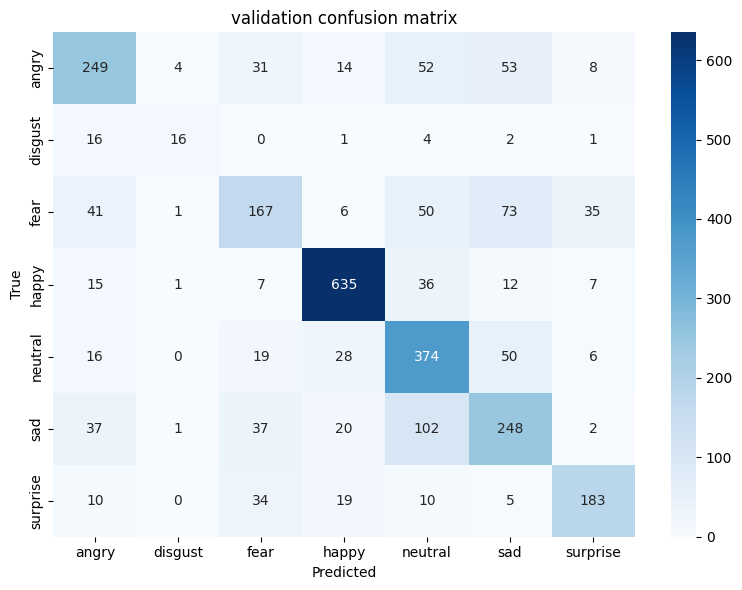

validation {
  "nll": 0.9352474212646484,
  "ece": 0.05514618381857872,
  "accuracy": 0.6837107377647919,
  "macro_f1": 0.638707379410458,
  "balanced_accuracy": 0.6226776627971474,
  "composite": 0.6612090585876249
}
              precision    recall  f1-score   support

       angry     0.6484    0.6058    0.6264       411
     disgust     0.6957    0.4000    0.5079        40
        fear     0.5661    0.4477    0.5000       373
       happy     0.8783    0.8906    0.8844       713
     neutral     0.5955    0.7586    0.6673       493
         sad     0.5598    0.5548    0.5573       447
    surprise     0.7562    0.7011    0.7276       261

    accuracy                         0.6837      2738
   macro avg     0.6714    0.6227    0.6387      2738
weighted avg     0.6840    0.6837    0.6804      2738

Summary: {'experiment': 'resnet18_128_bands', 'seed': 42, 'split_fingerprint': 'b29031b0e56e56c62e18f682144320f9b5cb240037446f93056d4120c449d2cc', 'best_epoch': 25, 'parameters': 112487

In [11]:
best_model, best_checkpoint = load_checkpoint(checkpoint_path, DEVICE)
val_logits, val_targets = predict(best_model, loaders['val'], DEVICE)
val_paths = split_manifest.loc[split_manifest['split'] == 'val', 'path'].tolist()
val_metrics = export_split_report(val_logits, val_targets, RUN_DIR, 'validation', val_paths)
latency = benchmark_latency_ms(best_model, CFG['image_size'], DEVICE, batch_sizes=(1,), runs=20)
summary = {
    'experiment': EXPERIMENT, 'seed': CFG['seed'], 'split_fingerprint': SPLIT_FINGERPRINT,
    'best_epoch': best_checkpoint['epoch'], 'parameters': parameter_count,
    'validation': val_metrics, 'device': str(DEVICE), 'latency': latency,
}
(RUN_DIR / 'summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print('Summary:', summary)

if RUN_FINAL_TEST:
    test_data = datasets.ImageFolder(DATA_ROOT / 'test', transform=build_transforms(CFG))
    check_classes(test_data)
    test_loader = DataLoader(test_data, batch_size=CFG['batch_size'], shuffle=False,
                             num_workers=resolve_num_workers(CFG))
    test_logits, test_targets = predict(best_model, test_loader, DEVICE)
    test_paths = [str(Path(path).relative_to(DATA_ROOT)) for path, _ in test_data.samples]
    export_split_report(test_logits, test_targets, RUN_DIR, 'test', test_paths)